# 05. O algoritmo genético e a maldição do vencedor

**Pergunta:** ajustar os hiperparâmetros dos 7 modelos e do meta-modelo melhora o Stacking 7 de verdade?

**Espaço de busca:** de 6 a 8 configurações por família + 6 valores do C do meta-modelo = **7.077.888**
combinações. **Truque que torna a busca viável:** cada configuração é treinada uma única vez por divisão e
as notas ficam em cache (`spamfilter.motor`); avaliar um cromossomo é só treinar o meta-modelo.

**Algoritmo:** população de 40, 30 gerações, torneio de 3, cruzamento uniforme, mutação de 15% por gene,
elitismo de 2. **Controle:** busca aleatória com o mesmo número de avaliações.

**Busca** em 10 divisões (sementes 11 e 12); **confirmação** em 20 divisões novas (sementes 201 a 204).

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from spamfilter import estatistica, genetico, graficos, metricas, modelos, saidas
from spamfilter.dados import carregar
from spamfilter.motor import Motor

base = carregar()
m = Motor(base, log=lambda *a: None)
BUSCA = m.adicionar_divisoes([11, 12], prefixo="b")
CONF = m.adicionar_divisoes([201, 202, 203, 204])
print(f"combinações possíveis: {int(np.prod(modelos.CARD)):,}".replace(",", "."))

combinações possíveis: 7.077.888


857 avaliações únicas em 92 s
MCC na busca | padrão 0.9732 | melhor do GA 0.9795 | melhor da busca aleatória 0.9784
  Reg. Logística  C=1, cw=balanced
  SVM RBF         k=500, C=30
  kNN cosseno     k=3, w=uniform
  MLP             h=(64,), a=0.0001
  Naive Bayes     a=0.1, norm=True, usa_tf=False
  Extra Trees     n=800, mf=sqrt, msl=1, cw=balanced
  LightGBM        n=400, eta=0.05, folhas=63
  meta-modelo     C=10.0


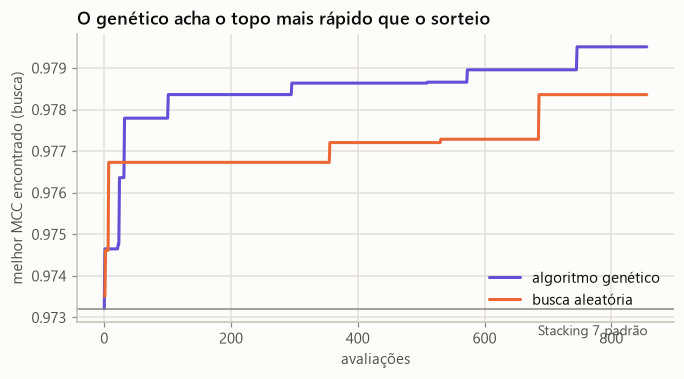

In [2]:
t0 = time.time()
apt = genetico.Aptidao(m, BUSCA)
melhor, hist = genetico.algoritmo_genetico(apt)
seq_ga = list(apt.memoria.values()); n = len(seq_ga)
seq_al = genetico.busca_aleatoria(apt, n)
print(f"{n} avaliações únicas em {time.time() - t0:.0f} s")
print(f"MCC na busca | padrão {apt(modelos.STACKING7_PADRAO):.4f} | melhor do GA {apt(melhor):.4f} | melhor da busca aleatória {max(seq_al):.4f}")
for fam, desc in modelos.descrever_stacking(melhor).items():
    print(f"  {fam:15s} {desc}")

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(np.maximum.accumulate(seq_ga), color=graficos.CATEGORICA[6], label="algoritmo genético")
ax.plot(np.maximum.accumulate(seq_al), color=graficos.CATEGORICA[1], label="busca aleatória")
ax.axhline(apt(modelos.STACKING7_PADRAO), color=graficos.TINTA_MUDA, lw=1)
ax.text(n, apt(modelos.STACKING7_PADRAO) - 0.0004, "Stacking 7 padrão", ha="right", va="top", color=graficos.TINTA_2, fontsize=9)
ax.set_xlabel("avaliações"); ax.set_ylabel("melhor MCC encontrado (busca)"); ax.legend(loc="lower right")
ax.set_title("O genético acha o topo mais rápido que o sorteio")
graficos.mostrar(fig, "05_ga_x_aleatoria")

## Quais famílias importam? (trocando um gene por vez a partir do melhor)

In [3]:
sens = genetico.sensibilidade(apt, melhor)
print(sens.round(4).to_string(index=False))

           gene   pior  melhor  amplitude
    kNN cosseno 0.9740  0.9795     0.0055
        SVM RBF 0.9749  0.9795     0.0046
meta-modelo (C) 0.9755  0.9795     0.0040
       LightGBM 0.9763  0.9801     0.0038
            MLP 0.9760  0.9795     0.0035
 Reg. Logística 0.9772  0.9795     0.0023
    Naive Bayes 0.9778  0.9795     0.0018
    Extra Trees 0.9780  0.9795     0.0015


## A medida honesta: sementes novas
O ganho medido na própria busca é otimista: o GA escolheu o melhor entre centenas de candidatos **nas mesmas
10 divisões** (a "maldição do vencedor"). Nas 20 divisões que a busca nunca viu, o ganho encolhe.

In [4]:
METODOS = {"Stacking 7 padrão": ("s", modelos.STACKING7_PADRAO), "Stacking 7 do GA (Especialista)": ("s", melhor),
           "LinearSVC padrão": ("l", modelos.LINEARSVC_PADRAO), "LinearSVC otimizado": ("l", modelos.LINEARSVC_OTIMIZADO)}
linhas = []
for c in CONF:
    yte = m.y_teste(c)
    for nome, (tipo, cfg) in METODOS.items():
        r = m.prever_stacking(cfg, c) if tipo == "s" else m.prever_linearsvc(cfg, c)
        linhas.append(dict(split=c, metodo=nome, **metricas.metricas(yte, *r)))
R = pd.DataFrame(linhas)
conf = R.groupby("metodo")[["mcc", "mcc_custo", "pr_auc", "real_lixeira_custo", "spam_passou_custo", "custo_por_mil"]].mean().loc[list(METODOS)]
print(conf.round(4).to_string())
ganho_busca = apt(melhor) - apt(modelos.STACKING7_PADRAO)
ganho_novas = float(conf.loc["Stacking 7 do GA (Especialista)", "mcc"] - conf.loc["Stacking 7 padrão", "mcc"])
print(f"\nganho do GA | na busca {ganho_busca:+.4f} | em sementes novas {ganho_novas:+.4f} "
      f"-> {1 - ganho_novas / ganho_busca:.0%} do ganho era otimismo da seleção")

P = R.pivot(index="split", columns="metodo", values="mcc")
CMP = estatistica.comparar(P, [("Stacking 7 do GA (Especialista)", "Stacking 7 padrão"), ("Stacking 7 do GA (Especialista)", "LinearSVC otimizado"),
                               ("Stacking 7 padrão", "LinearSVC otimizado")], 3310, 828, runs=4)
print(CMP[["A", "B", "dif", "p_holm", "P_A_melhor", "P_equivalentes", "P_B_melhor"]].round(4).to_string(index=False))

                                    mcc  mcc_custo  pr_auc  real_lixeira_custo  spam_passou_custo  custo_por_mil
metodo                                                                                                          
Stacking 7 padrão                0.9734     0.9554  0.9973              0.0041             0.0531        41.5130
Stacking 7 do GA (Especialista)  0.9744     0.9615  0.9976              0.0037             0.0456        36.6179
LinearSVC padrão                 0.9600     0.9392  0.9952              0.0048             0.0744        52.0293
LinearSVC otimizado              0.9627     0.9406  0.9956              0.0045             0.0731        50.0340

ganho do GA | na busca +0.0063 | em sementes novas +0.0010 -> 85% do ganho era otimismo da seleção
                              A                   B    dif  p_holm  P_A_melhor  P_equivalentes  P_B_melhor
Stacking 7 do GA (Especialista) LinearSVC otimizado 0.0117  0.0415      0.6506          0.3493      0.0000
        

## O piso estatístico: mais sementes não resolvem
As divisões reusam os mesmos ~4100 e-mails, então o erro-padrão corrigido tem um piso.

In [5]:
dp = (P["Stacking 7 do GA (Especialista)"] - P["LinearSVC otimizado"]).std(ddof=1)
piso = pd.DataFrame([dict(folds=J, menor_dif_detectavel=estatistica.menor_diferenca_detectavel(dp, J, 828 / 3310)) for J in [5, 10, 20, 50, 100, 1000]])
print(piso.round(4).to_string(index=False))

 folds  menor_dif_detectavel
     5                0.0106
    10                0.0093
    20                0.0086
    50                0.0082
   100                0.0080
  1000                0.0079


In [6]:
saidas.gravar("05_genetico", {
    "genetico": dict(combinacoes=int(np.prod(modelos.CARD)), avaliacoes=n, melhor=list(melhor), melhor_descricao=modelos.descrever_stacking(melhor),
                     mcc_busca_padrao=apt(modelos.STACKING7_PADRAO), mcc_busca_ga=apt(melhor), mcc_busca_aleatoria=max(seq_al),
                     ganho_busca=ganho_busca, ganho_sementes_novas=ganho_novas, fracao_otimismo=1 - ganho_novas / ganho_busca,
                     curva_ga=np.maximum.accumulate(seq_ga).round(5), curva_aleatoria=np.maximum.accumulate(seq_al).round(5),
                     historico=hist, sensibilidade=sens, confirmacao=conf.reset_index(), comparacoes=CMP, piso=piso),
}, fonte="scripts/05_algoritmo_genetico.py")
print("gravado: resultados/05_genetico.json")

gravado: resultados/05_genetico.json
